[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/07_literature_validation.ipynb)

# 7 · Validation against published results

This notebook reruns cases from five papers and compares the toolkit's numbers with the published
ones. Some published values are **measurements**; others are **results from the authors' own
models**. Both are useful checks, but only measurements test the physics, so each case says which
kind it is.

| Paper | Kind of data | What is compared |
|---|---|---|
| Pan (1986) | measurement | H₂ recovery from ammonia purge gas, cellulose acetate hollow fibres |
| Merkel et al. (2010) | model results | flue-gas CO₂ capture: pressure-ratio limit, cross-flow against counter-current, three membranes |
| Coker et al. (1998) | model results | a five-component refinery H₂ module with bore pressure drop |
| Makaruk et al. (2010) | model results | two-stage biogas cascade: specific power and membrane area |
| Feng et al. (1999) | measurement (rules stated in the text) | air separation: purity–productivity, temperature and pressure effects |

The full references are in `LITERATURE`.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


In [2]:
checks = []          # collected at the end
def check(case, quantity, paper, model, kind):
    checks.append(dict(case=case, quantity=quantity, published=paper, toolkit=model, data=kind))
for k in ("Pan1986", "Merkel2010", "Coker1998", "Makaruk2010", "Feng1999"):
    print("-", LITERATURE[k])

- Pan, C.Y. (1986) 'Gas separation by high-flux, asymmetric hollow-fiber membrane', AIChE J. 32, 2020-2027. doi:10.1002/aic.690321212
- Merkel, T.C., Lin, H., Wei, X. and Baker, R. (2010) 'Power plant post-combustion carbon dioxide capture: an opportunity for membranes', J. Membr. Sci. 359, 126-139. doi:10.1016/j.memsci.2009.10.041
- Coker, D.T., Freeman, B.D. and Fleming, G.K. (1998) 'Modeling multicomponent gas separation using hollow-fiber membrane contactors', AIChE J. 44, 1289-1302. doi:10.1002/aic.690440607
- Makaruk, A., Miltner, M. and Harasek, M. (2010) 'Membrane biogas upgrading processes for the production of natural gas substitute', Sep. Purif. Technol. 74, 83-92. doi:10.1016/j.seppur.2010.05.010
- Feng, X., Ivory, J. and Rajan, V.S.V. (1999) 'Air separation by integrally asymmetric hollow-fiber membranes', AIChE J. 45, 2142-2152. doi:10.1002/aic.690451013


## 1 · Pan (1986): hydrogen recovery, measured

Pan ran a small module of asymmetric cellulose acetate hollow fibres on a simulated ammonia purge
gas: 51.78 % H₂, 24.69 % N₂, 19.57 % CH₄ and 3.96 % Ar, at 6964 kPa feed, 1123 kPa permeate and
25 °C. The pure-gas permeabilities are in the preset.

The text gives one measured point in full: at a stage cut of 0.55, run co-currently, the permeate
contained **86.6 % H₂** and the residue **8.8 % H₂**.

Pan's main conclusion was that in high-flux *asymmetric* membranes the porous support stops local
permeate from mixing. The skin therefore sees **cross-flow** whatever the module's flow
arrangement.

In [3]:
m = Membrane(MEMBRANE_PRESETS["Cellulose acetate H2 recovery (Pan 1986)"])
xf = FEED_PRESETS["ammonia purge gas, NH3-free (Pan 1986)"]
rows = {}
for p in PATTERNS:
    r = solve_stage(m, xf, 0.55, 69.64, 11.23, p)
    rows[LABELS[p]] = {"permeate H2": r.y_perm[0], "residue H2": r.x_ret[0]}
rows["Measured (Pan, co-current run)"] = {"permeate H2": 0.866, "residue H2": 0.088}
pan = pd.DataFrame(rows).T
check("Pan 1986, θ = 0.55", "permeate H2", 0.866, pan.loc["Cross-flow", "permeate H2"], "measured")
check("Pan 1986, θ = 0.55", "residue H2", 0.088, pan.loc["Cross-flow", "residue H2"], "measured")
pan.round(3)

,permeate H2,residue H2
Well-mixed,0.805,0.167
Cross-flow,0.886,0.067
Co-current,0.830,0.136
Counter-current,0.900,0.051
"Measured (Pan, co-current run)",0.866,0.088


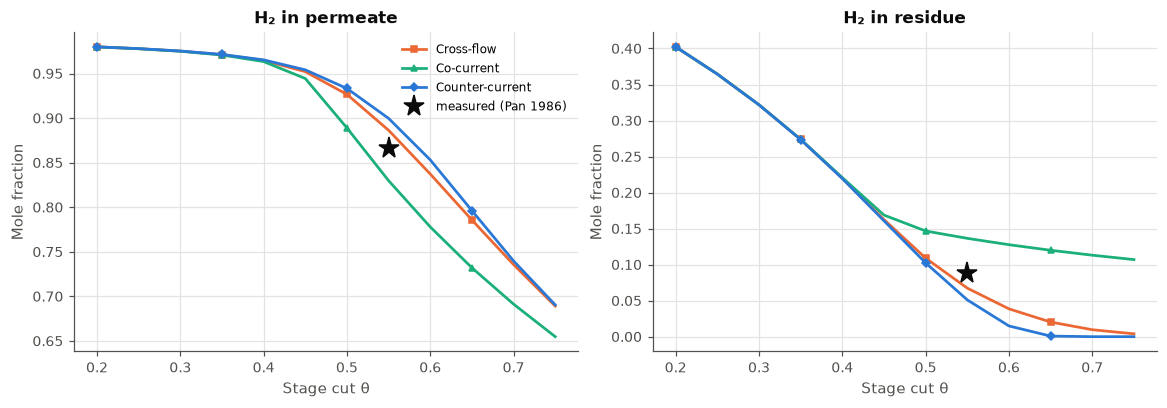

In [4]:
th = np.linspace(0.2, 0.75, 12)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True)
for p in ["cross_flow", "cocurrent", "countercurrent"]:
    res = [solve_stage(m, xf, t, 69.64, 11.23, p) for t in th]
    ax[0].plot(th, [r.y_perm[0] for r in res], color=COLORS[p], marker=MARKERS[p], ms=4, markevery=3, label=LABELS[p])
    ax[1].plot(th, [r.x_ret[0] for r in res], color=COLORS[p], marker=MARKERS[p], ms=4, markevery=3, label=LABELS[p])
for a, v, t in [(ax[0], 0.866, "H₂ in permeate"), (ax[1], 0.088, "H₂ in residue")]:
    a.plot([0.55], [v], marker="*", ms=14, color="#0b0b0b", ls="none", label="measured (Pan 1986)")
    a.set(xlabel="Stage cut θ", ylabel="Mole fraction", title=t)
ax[0].legend(fontsize=8);

**Result.** The measured point lies closest to the **cross-flow** model, as Pan concluded, and far
from the co-current model the module was nominally run as. The toolkit's cross-flow model
over-predicts the separation slightly (88.6 % against 86.6 %). Pan reports the same deviation
above a stage cut of 0.55 and puts it down to back-diffusion in the porous support at high
recovery. The lesson for users: with high-flux asymmetric fibres, use `cross_flow` even when the
module is built co- or counter-current.

## 2 · Merkel et al. (2010): flue-gas CO₂ capture, model results

Merkel et al. used the Polaris membrane (CO₂ 1000 GPU, CO₂/N₂ = 50) to show why flue-gas capture is
**pressure-ratio limited**. These are results from their own models, so the comparison checks that
the two sets of equations agree.

### 2a · The pressure-ratio limit (their Figs. 3 and 4)
The feed is 10 % CO₂ at 5 bar, the permeate is at 1 bar, and the stage cut is 1 %. The selectivity
is raised by lowering the N₂ permeance. However selective the membrane, the permeate cannot
exceed φ·x = 5 × 10 % = 50 % CO₂.

selectivity 1: 0.100 (paper 0.10);  selectivity 10 000: 0.490 (paper: approaches 0.50)


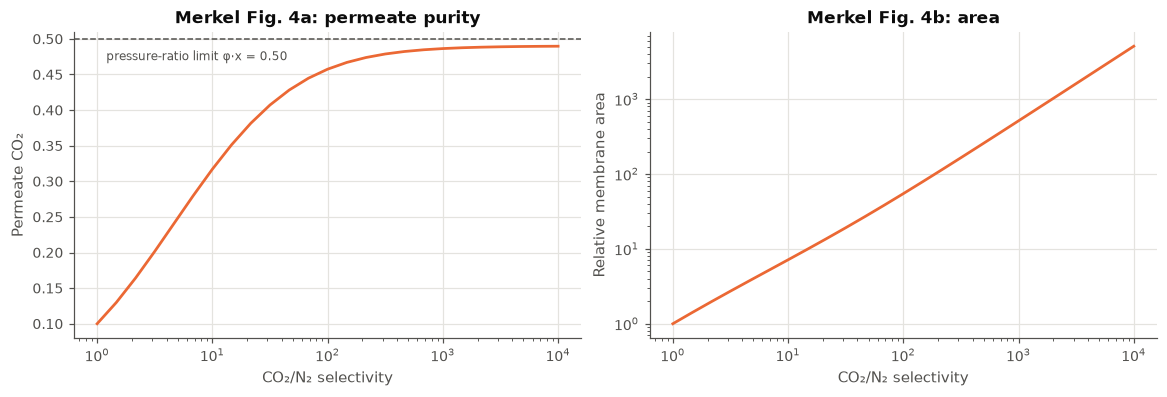

In [5]:
alphas = np.logspace(0, 4, 25)
y, area = [], []
for a in alphas:
    r = cross_flow(Membrane({"CO2": 1000, "N2": 1000 / a}), [0.10, 0.90], 0.01, 5.0, 1.0, profile=False)
    y.append(r.y_perm[0]); area.append(r.area)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5), constrained_layout=True)
ax[0].semilogx(alphas, y, color=COLORS["cross_flow"]); ax[0].axhline(0.5, color="#52514e", ls="--", lw=1)
ax[0].text(1.2, 0.47, "pressure-ratio limit φ·x = 0.50", color="#52514e", fontsize=8)
ax[0].set(xlabel="CO₂/N₂ selectivity", ylabel="Permeate CO₂", title="Merkel Fig. 4a: permeate purity")
ax[1].loglog(alphas, np.array(area) / area[0], color=COLORS["cross_flow"])
ax[1].set(xlabel="CO₂/N₂ selectivity", ylabel="Relative membrane area", title="Merkel Fig. 4b: area");
print(f"selectivity 1: {y[0]:.3f} (paper 0.10);  selectivity 10 000: {y[-1]:.3f} (paper: approaches 0.50)")
check("Merkel 2010 Fig. 4", "permeate CO2 at α = 1", 0.10, y[0], "model")

Merkel et al. conclude that the optimum selectivity at φ = 5 lies between 20 and 40. Above that,
purity barely improves while the membrane area climbs steeply. The curves above show the same
behaviour.

### 2b · Cross-flow against counter-current (their Fig. 6)
The feed is 500 m³(STP)/s with 13 % CO₂, cleaned to 2.1 % CO₂ in the residue; the permeate is
under vacuum at 0.22 bar. The paper does not state the feed pressure. A blower of 7.2 MW at 80 %
efficiency raises 500 m³/s by about 10 %, so the feed is taken as **1.1 bar**, which gives the
pressure ratio of 5 used throughout the paper.

In [6]:
from scipy.optimize import brentq
m = Membrane(MEMBRANE_PRESETS["Polaris CO2/N2 (Merkel 2010)"])
xf = FEED_PRESETS["flue gas, 13% CO2 (Merkel 2010)"]
F = 500 / 0.022414
ea = EnergyAssumptions(eta_vacuum=0.8, p_discharge=1.0, max_stage_ratio=10)   # single-stage vacuum pump
paper = {"cross_flow": (0.289, 11.0, 56.3), "countercurrent": (0.406, 6.8, 38.8)}
rows = {}
for p, (yp, ap, wp) in paper.items():
    th = brentq(lambda t: solve_stage(m, xf, t, 1.1, 0.22, p, F).x_ret[0] - 0.021, 0.05, 0.9, xtol=1e-7)
    r = solve_stage(m, xf, th, 1.1, 0.22, p, F)
    wv = stage_energy(r, ea)["vacuum_pump_kW"] / 1e3
    rows[LABELS[p]] = {"stage cut": th, "permeate CO2 (toolkit)": r.y_perm[0], "permeate CO2 (paper)": yp,
                       "area MM m2 (toolkit)": r.area / 1e6, "area MM m2 (paper)": ap,
                       "vacuum MW (toolkit)": wv, "vacuum MW (paper)": wp}
    check(f"Merkel 2010 Fig. 6, {LABELS[p]}", "permeate CO2", yp, r.y_perm[0], "model")
    check(f"Merkel 2010 Fig. 6, {LABELS[p]}", "area, million m2", ap, r.area / 1e6, "model")
    check(f"Merkel 2010 Fig. 6, {LABELS[p]}", "vacuum power, MW", wp, wv, "model")
pd.DataFrame(rows).T.round(3)

,stage cut,permeate CO2 (toolkit),permeate CO2 (paper),area MM m2 (toolkit),area MM m2 (paper),vacuum MW (toolkit),vacuum MW (paper)
Cross-flow,0.406,0.289,0.289,11.029,11.0,52.330,56.3
Counter-current,0.283,0.407,0.406,6.440,6.8,36.177,38.8


**Result.** Permeate purity and membrane area agree within a few per cent, and counter-current
needs about 40 % less area than cross-flow in both models. The vacuum power comes out lower in the
toolkit. Merkel et al. do not give their compressor model, and their flue gas carries water and
oxygen that also have to be pumped, so this is the least certain comparison.

### 2c · Three membranes (their Table 1)
Feed 2.0 bar, permeate 0.2 bar, 90 % CO₂ capture, standard cross-flow modules. The paper's feed was
wet flue gas (11.6 % CO₂, 11 % H₂O, 4.2 % O₂); here it is treated as dry CO₂/N₂ with 13 % CO₂,
because permeances for water and oxygen are not given.

In [7]:
paper = {"base case (1000 GPU, α 50)": (1000, 50, 0.46, 2.1),
         "membrane A (100 GPU, α 200)": (100, 200, 0.54, 59.0),
         "membrane B (1000 GPU, α 200)": (1000, 200, 0.55, 5.7)}
rows, base = {}, None
for name, (q, a, yp, ap) in paper.items():
    mm = Membrane({"CO2": q, "N2": q / a})
    th = brentq(lambda t: cross_flow(mm, xf, t, 2.0, 0.2, profile=False).recovery(0) - 0.90, 0.05, 0.95, xtol=1e-8)
    r = cross_flow(mm, xf, th, 2.0, 0.2, profile=False)
    base = base or r.area
    rows[name] = {"permeate CO2 (toolkit)": r.y_perm[0], "permeate CO2 (paper)": yp,
                  "area / base (toolkit)": r.area / base, "area / base (paper)": ap / 2.1}
    check("Merkel 2010 Table 1, " + name.split(" (")[0], "permeate CO2", yp, r.y_perm[0], "model")
pd.DataFrame(rows).T.round(3)

,permeate CO2 (toolkit),permeate CO2 (paper),area / base (toolkit),area / base (paper)
"base case (1000 GPU, α 50)",0.441,0.46,1.000,1.000
"membrane A (100 GPU, α 200)",0.514,0.54,29.581,28.095
"membrane B (1000 GPU, α 200)",0.514,0.55,2.958,2.714


**Result.** The ranking and the area ratios (about 28 and 2.7 times the base case) are reproduced.
Purities come out 2–3 points lower, as expected: in the paper's wet feed, water permeates fast and
acts as a built-in sweep, an effect Merkel et al. describe themselves. The central message holds:
the four-times more selective membrane B needs *more* area than the base case, because the
separation is pressure-ratio limited.

## 3 · Coker et al. (1998): a five-component refinery module, model results

The case is a shell-side-feed hollow-fibre module with permeate in the bores:
- 500 000 fibres, 300/150 µm outer/inner diameter, 0.8 m active length;
- 283.2 Nm³/h of hydrotreater purge gas at 42.4 bar and 50 °C, permeate at 7.9 bar;
- counter-current flow, with Hagen–Poiseuille pressure drop in the bores.

Coker et al. report a **total permeate recovery (stage cut) of 94.6 %**. They also note that at
this recovery H₂ is stripped from the feed early, so only about 20 % of the area does useful H₂
separation, and that methane passes through a concentration maximum.

HollowFibreModule(area=377 m2, n_fibres=5e+05, L=0.8 m, d_i=150 um, d_o=300 um)
stage cut: toolkit 0.9463, paper 0.946;  bore pressure rise 0.029 bar
feed-side H2 falls below 1 % at 0.20 of the length


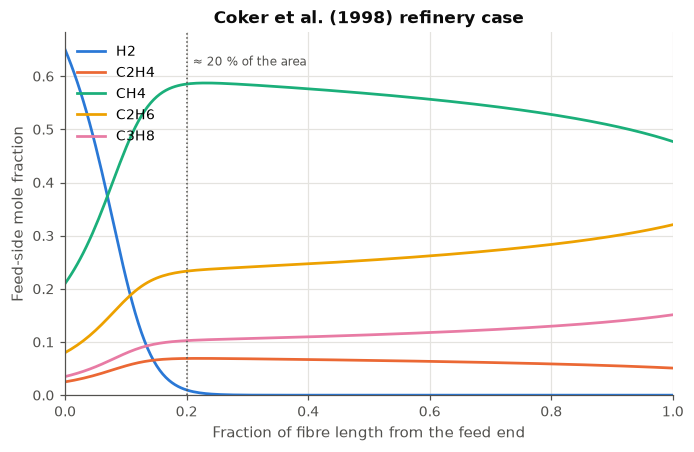

In [8]:
m = Membrane(MEMBRANE_PRESETS["Polysulfone-like H2/hydrocarbons (Coker 1998)"])
xf = FEED_PRESETS["refinery hydrotreater purge (Coker 1998)"]
mod = HollowFibreModule(500_000, length=0.8, d_inner=150e-6, d_outer=300e-6)
r = rate_module(m, xf, nm3h_to_mols(283.2), 42.4, 7.9, mod, "countercurrent", pressure_drop=True, T=323.15)
print(mod); print(f"stage cut: toolkit {r.theta:.4f}, paper 0.946;  bore pressure rise {r.extra['bore_dp_bar']:.3f} bar")
check("Coker 1998 refinery module", "stage cut", 0.946, r.theta, "model")
pr = r.profile
fig, ax = plt.subplots(figsize=(6.2, 4), constrained_layout=True)
for i, c in enumerate(m.components):
    ax.plot(pr["area_fraction"], pr["x"][i], color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"][i], label=c)
ax.axvline(0.2, color="#52514e", ls=":", lw=1); ax.text(0.21, 0.62, "≈ 20 % of the area", color="#52514e", fontsize=8)
ax.set(xlabel="Fraction of fibre length from the feed end", ylabel="Feed-side mole fraction",
       title="Coker et al. (1998) refinery case", xlim=(0, 1), ylim=(0, None)); ax.legend();
h2 = pr["x"][0]
print(f"feed-side H2 falls below 1 % at {pr['area_fraction'][np.argmax(h2 < 0.01)]:.2f} of the length")

**Result.** The stage cut matches (94.65 % against 94.6 %), H₂ is gone from the feed side within
the first ~20 % of the fibre, and methane peaks partway along, as Coker et al. describe. Two notes
on the scanned paper: the module area must be 377 m² (π × 300 µm × 0.8 m × 500 000; the "317" in
the scan is a misread), and the component order of Table 3 was confirmed by this run.

## 4 · Makaruk et al. (2010): two-stage biogas cascade, model results

Makaruk et al. recommend a **two-stage cascade with recycle**: the retentate of stage 1 is polished
in stage 2, whose permeate returns to the compressor. In the toolkit this is
`two_stage_stripping`. Their basis:
- 1000 Nm³/h of biogas with 60 % CH₄, a product with 98 % CH₄;
- 10 bar feed, counter-current modules;
- CO₂ permeance 100 GPU;
- a two-stage compressor with 80 % isentropic and 90 % mechanical efficiency.

For the two heat-demand cases in the paper, 5 % and 15 %, the methane recoveries are 93.8 % and
81.2 %. Their headline figure is a specific power of **about 0.3 kWh per Nm³ of product**.

In [9]:
from scipy.optimize import least_squares
xf = FEED_PRESETS["biogas, 60% CH4 (Makaruk 2010)"]; F = nm3h_to_mols(1000)
ea = EnergyAssumptions(eta_compressor=0.8 * 0.9)

def cascade(alpha, th, pattern):
    mm = Membrane({"CO2": 100.0, "CH4": 100.0 / alpha})
    return two_stage_stripping(mm, xf, F, StageSpec(th[0], 10, 1, pattern), StageSpec(th[1], 10, 1, pattern), ea=ea)

def design(alpha, recovery, pattern, x0=(0.3, 0.3)):
    # stage cuts that give 98 % CH4 at the requested recovery
    f = lambda th: (lambda r: [r.purity("retentate 2", "CH4") - 0.98,
                               r.recovery("retentate 2", "CH4") - recovery])(cascade(alpha, th, pattern))
    th = least_squares(f, x0, bounds=([0.05, 0.005], [0.8, 0.9]), xtol=1e-7, ftol=1e-7, diff_step=1e-3).x
    r = cascade(alpha, th, pattern)
    return dict(pattern=pattern, alpha=alpha, recovery=recovery, theta1=th[0], theta2=th[1],
                purity=r.purity("retentate 2", "CH4"), area_m2=r.total_area,
                kWh_per_Nm3=r.total_power_kW / mols_to_nm3h(r.streams["retentate 2"].sum()),
                recycle_ratio=r.recycle_ratio())

# selectivity sweep with cross-flow stages (fast) ...
mk = pd.DataFrame([design(a, rec, "cross_flow") for rec in (0.938, 0.812) for a in (12, 22, 35, 50)])
# ... and the alpha = 35 cases with counter-current stages, as in the paper (a few minutes)
cc = pd.DataFrame([design(35, rec, "countercurrent",
                          x0=mk[(mk.alpha == 35) & (mk.recovery == rec)][["theta1", "theta2"]].iloc[0].values)
                   for rec in (0.938, 0.812)])
for _, row in cc.iterrows():
    check(f"Makaruk 2010, α = 35, recovery {row.recovery:.1%}", "kWh per Nm3 product", 0.3,
          row.kWh_per_Nm3, "model (approximate)")
pd.concat([mk, cc]).round(3)

,pattern,alpha,recovery,theta1,theta2,purity,area_m2,kWh_per_Nm3,recycle_ratio
0,cross_flow,12,0.938,0.182,0.699,0.980,2936.527,0.456,1.334
1,cross_flow,22,0.938,0.277,0.483,0.980,2620.397,0.300,0.536
2,cross_flow,35,0.938,0.330,0.335,0.980,2784.664,0.252,0.289
3,cross_flow,50,0.938,0.358,0.248,0.980,3108.834,0.232,0.189
4,cross_flow,12,0.812,0.361,0.441,0.980,1996.914,0.314,0.392
5,cross_flow,22,0.812,0.445,0.208,0.980,2062.810,0.255,0.131
6,cross_flow,35,0.812,0.480,0.088,0.980,2334.083,0.237,0.048
7,cross_flow,50,0.812,0.497,0.022,0.980,2669.802,0.228,0.011
0,countercurrent,35,0.938,0.347,0.282,0.980,2143.990,0.239,0.226
1,countercurrent,35,0.812,0.502,0.005,0.982,1810.961,0.227,0.002


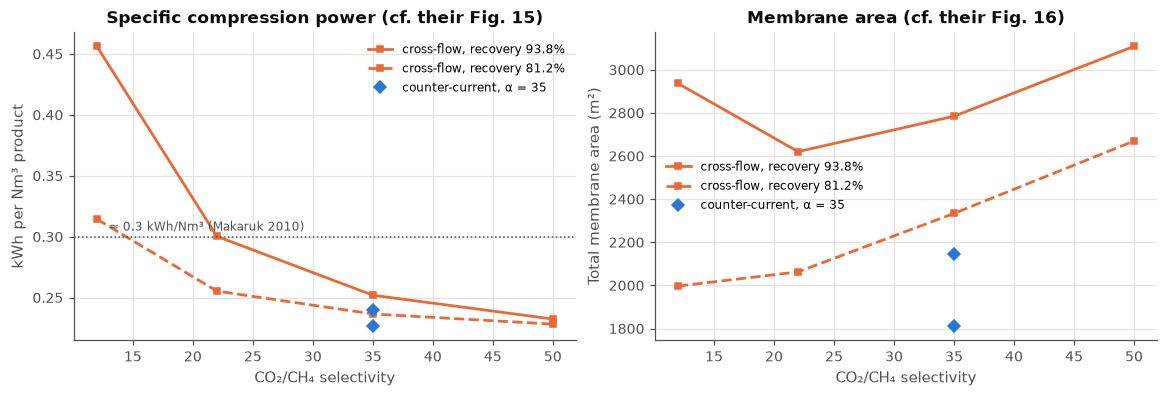

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5), constrained_layout=True)
for rec, ls in [(0.938, "-"), (0.812, "--")]:
    d = mk[mk.recovery == rec]
    ax[0].plot(d.alpha, d.kWh_per_Nm3, color=COLORS["cross_flow"], ls=ls, marker="s", ms=4, label=f"cross-flow, recovery {rec:.1%}")
    ax[1].plot(d.alpha, d.area_m2, color=COLORS["cross_flow"], ls=ls, marker="s", ms=4, label=f"cross-flow, recovery {rec:.1%}")
ax[0].plot(cc.alpha, cc.kWh_per_Nm3, color=COLORS["countercurrent"], ls="none", marker="D", ms=6, label="counter-current, α = 35")
ax[1].plot(cc.alpha, cc.area_m2, color=COLORS["countercurrent"], ls="none", marker="D", ms=6, label="counter-current, α = 35")
ax[0].axhline(0.3, color="#52514e", lw=1, ls=":"); ax[0].text(13, 0.305, "≈ 0.3 kWh/Nm³ (Makaruk 2010)", fontsize=8, color="#52514e")
ax[0].set(xlabel="CO₂/CH₄ selectivity", ylabel="kWh per Nm³ product", title="Specific compression power (cf. their Fig. 15)")
ax[1].set(xlabel="CO₂/CH₄ selectivity", ylabel="Total membrane area (m²)", title="Membrane area (cf. their Fig. 16)")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8);

**Result.** Both of Makaruk's design findings are reproduced:
- **Optimum selectivity:** the selectivity that needs the least membrane area comes out at
  **α ≈ 22 for 93.8 % recovery and α ≈ 12 for 81.2 %**, the values reported in their Fig. 16.
  Area rises again at higher selectivity because, with the CO₂ permeance fixed, a more selective
  membrane lets less gas through per square metre.
- **Specific compression power:** 0.23–0.30 kWh per Nm³ of product (0.24 with counter-current
  modules at α = 35), close to their "around 0.3 kWh/m³". Like their Fig. 15, it falls with
  selectivity and flattens above about 30.
- **Near-single-stage limit:** at 81.2 % recovery and α = 35 the optimiser drives the second
  stage almost to zero. Makaruk et al. note the same: for the higher heat demand a single stage
  is sufficient.

Their figures can only be read as trends from the scan, so these checks are approximate.

## 5 · Feng et al. (1999): air separation, measured

Feng et al. tested a module of 368 asymmetric fibres, 25 cm long and 160/80 µm in diameter, with
bore-side feed in counter-current flow. Their feed was 20.5 % O₂ air at 100 psig (690 kPa gauge),
with the permeate at local atmospheric pressure, 70 cmHg (93.3 kPa). The pure-gas permeances
follow Arrhenius laws with activation energies of 19.3 kJ/mol for O₂ and 27.6 kJ/mol for N₂.

The measured points are only in figures, but the text states three quantitative findings, which
are checked here:
1. Nitrogen productivity roughly **halves** from 95 % to 98 % N₂ purity.
2. From 23 to 45 °C at 95 % N₂, productivity rises by about **75 %** and recovery falls by about
   **8 points**. At 35 % O₂, productivity about **doubles** and recovery falls by about **6 points**.
3. At 95 % N₂, adding **50 psi** to the feed is about **equivalent** to pulling a **57 cmHg vacuum**
   on the permeate.

Productivity is the product flow per unit membrane area.

In [11]:
from gasmem.properties import GPU, R
Q0 = {"O2": 30.78e-10 / GPU, "N2": 5.7e-10 / GPU}; E = {"O2": 19.3e3, "N2": 27.6e3}
def feng_membrane(T_C):
    T = T_C + 273.15
    return Membrane({g: Q0[g] * np.exp(-E[g] / R * (1 / T - 1 / 296.15)) for g in Q0})
xf = [0.205, 0.795]; patm = 0.933; p100 = 6.895 + patm

def n2_case(purity, T_C=23, ph=p100, pl=patm):
    mm = feng_membrane(T_C)
    th = brentq(lambda t: countercurrent(mm, xf, t, ph, pl, profile=False).x_ret[1] - purity, 0.25, 0.9, xtol=1e-8)
    r = countercurrent(mm, xf, th, ph, pl, profile=False)
    return r.retentate_flow * r.x_ret[1] / r.area, r.recovery("N2", "retentate")

def o2_case(purity, T_C=23):
    mm = feng_membrane(T_C)
    th = brentq(lambda t: countercurrent(mm, xf, t, p100, patm, profile=False).y_perm[0] - purity, 0.02, 0.6, xtol=1e-8)
    r = countercurrent(mm, xf, th, p100, patm, profile=False)
    return r.permeate_flow * r.y_perm[0] / r.area, r.recovery("O2")

p95, r95 = n2_case(0.95); p98, _ = n2_case(0.98); p95h, r95h = n2_case(0.95, 45)
o35, ro35 = o2_case(0.35); o35h, ro35h = o2_case(0.35, 45)
pa, _ = n2_case(0.95, ph=p100 + 3.447); pb, _ = n2_case(0.95, pl=patm - 0.760)
feng = pd.DataFrame([
    ("productivity ratio, 98 % / 95 % N2", 0.5, p98 / p95),
    ("23→45 °C, 95 % N2: productivity gain", 0.75, p95h / p95 - 1),
    ("23→45 °C, 95 % N2: recovery change (points)", -8, (r95h - r95) * 100),
    ("23→45 °C, 35 % O2: productivity ratio", 2.0, o35h / o35),
    ("23→45 °C, 35 % O2: recovery change (points)", -6, (ro35h - ro35) * 100),
    ("+50 psi feed vs 57 cmHg vacuum: productivity ratio", 1.0, pa / pb),
], columns=["finding", "Feng et al. (approx.)", "toolkit"]).set_index("finding")
for f, row in feng.iterrows():
    check("Feng 1999", f, row.iloc[0], row.iloc[1], "measured (approximate)")
feng.round(2)

,Feng et al. (approx.),toolkit
finding,,
"productivity ratio, 98 % / 95 % N2",0.50,0.57
"23→45 °C, 95 % N2: productivity gain",0.75,0.57
"23→45 °C, 95 % N2: recovery change (points)",-8.00,-7.72
"23→45 °C, 35 % O2: productivity ratio",2.00,2.12
"23→45 °C, 35 % O2: recovery change (points)",-6.00,-8.29
+50 psi feed vs 57 cmHg vacuum: productivity ratio,1.00,1.13


**Result.** All three findings are reproduced in direction and roughly in size by an ideal
counter-current model with constant pure-gas permeances. The productivity gain on heating comes out
smaller than measured (+57 % against +75 %). Feng et al. note that their model also slightly
over-predicts purity at high stage cut, which they attribute to concentration polarisation in the
porous support. The toolkit does not model that effect, nor the feed-side pressure drop of
bore-side feed.

## Summary

In [12]:
summary = pd.DataFrame(checks)
def diff(row):
    try:
        return f"{(row.toolkit - row.published) / abs(row.published) * 100:+.0f} %"
    except ZeroDivisionError:
        return ""
summary["difference"] = summary.apply(diff, axis=1)
summary.style.format({"published": "{:.3g}", "toolkit": "{:.3g}"}).hide(axis="index")

case,quantity,published,toolkit,data,difference
"Pan 1986, θ = 0.55",permeate H2,0.866,0.886,measured,+2 %
"Pan 1986, θ = 0.55",residue H2,0.088,0.0674,measured,-23 %
Merkel 2010 Fig. 4,permeate CO2 at α = 1,0.1,0.1,model,+0 %
"Merkel 2010 Fig. 6, Cross-flow",permeate CO2,0.289,0.289,model,+0 %
"Merkel 2010 Fig. 6, Cross-flow","area, million m2",11,11,model,+0 %
"Merkel 2010 Fig. 6, Cross-flow","vacuum power, MW",56.3,52.3,model,-7 %
"Merkel 2010 Fig. 6, Counter-current",permeate CO2,0.406,0.407,model,+0 %
"Merkel 2010 Fig. 6, Counter-current","area, million m2",6.8,6.44,model,-5 %
"Merkel 2010 Fig. 6, Counter-current","vacuum power, MW",38.8,36.2,model,-7 %
"Merkel 2010 Table 1, base case",permeate CO2,0.46,0.441,model,-4 %


**Overall.** Where the published numbers come from models with the same assumptions as the
toolkit, agreement is within a few per cent: Merkel's purities and areas, and Coker's stage cut.
Against measurements, the ideal models capture the trends and land within a few percentage points
of composition, provided the right flow pattern is chosen (cross-flow for Pan's high-flux
asymmetric fibres). The remaining gaps all trace back to effects the toolkit deliberately leaves
out:
- concentration polarisation and back-diffusion in the porous support;
- mixed-gas permeances that differ from pure-gas values;
- water and oxygen in real flue gas;
- feed-side pressure drop.